In [342]:
from hmmlearn import hmm
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [343]:
model = hmm.GaussianHMM(n_components=5, covariance_type="full", n_iter=1000,random_state=42)
train_df=pd.read_csv('train_df.csv')
train_df=train_df.drop(columns=["Unnamed: 0"])
model.fit(train_df)

,n_components,5
,covariance_type,'full'
,random_state,42
,n_iter,1000
,min_covar,0.001
,startprob_prior,1.0
,transmat_prior,1.0
,means_prior,0
,means_weight,0
,covars_prior,0.01
,covars_weight,1


In [344]:
print(train_df.shape, train_df.columns.tolist())
print(train_df.head())

(3706, 4) ['daily_returns', 'sign_persistence', 'rolling_volatility', 'trend']
   daily_returns  sign_persistence  rolling_volatility     trend
0      -0.455275         -0.743581            0.769154  1.620019
1      -1.058761         -0.278561            0.796237  1.430789
2       0.191674         -0.278561            0.790002  1.243011
3       1.626112          0.186459            0.903506  1.104814
4       1.262184          0.651479            0.941577  0.967679


In [345]:
states = model.predict(train_df)
print(pd.Series(states).value_counts().sort_index())

0    1135
1     931
2     831
3     318
4     491
Name: count, dtype: int64


In [346]:
state_analysis = train_df.copy()
state_analysis["state"] = states

print(state_analysis.groupby("state").mean().round(3))

       daily_returns  sign_persistence  rolling_volatility  trend
state                                                            
0             -0.011             0.146              -0.093  0.150
1             -0.015             0.235              -0.440 -0.215
2              0.027            -0.313              -0.750  0.466
3             -0.028            -0.701               2.145 -1.765
4              0.026             0.202               0.929  0.415


In [347]:
print(state_analysis["state"].value_counts().sort_index())

state
0    1135
1     931
2     831
3     318
4     491
Name: count, dtype: int64


In [348]:
print(pd.Series(
    model.transmat_.diagonal(),
    index=range(model.n_components),
    name="probability_of_staying"
).round(3))

0    0.968
1    0.957
2    0.971
3    0.968
4    0.962
Name: probability_of_staying, dtype: float64


In [349]:
# print(pd.Series(
#     model.transmat_[],
#     index=range(model.n_components),
#     name="transition_from_state_5"
# ).round(3))

In [350]:
s = pd.Series(states)
print(((s == 5) & (s.shift(1) == 5)).sum())

0


In [351]:
%store -r means
%store -r standard_deviations

print(state_analysis.groupby("state")["daily_returns"].mean().mul(standard_deviations["daily_returns"]).add(means["daily_returns"]))

state
0    0.000257
1    0.000197
2    0.000766
3    0.000018
4    0.000755
Name: daily_returns, dtype: float64


In [352]:
print(state_analysis.loc[state_analysis["state"] == 1, "daily_returns"].describe())

count    931.000000
mean      -0.014891
std        0.620103
min       -2.145153
25%       -0.388276
50%        0.001950
75%        0.389984
max        1.973207
Name: daily_returns, dtype: float64


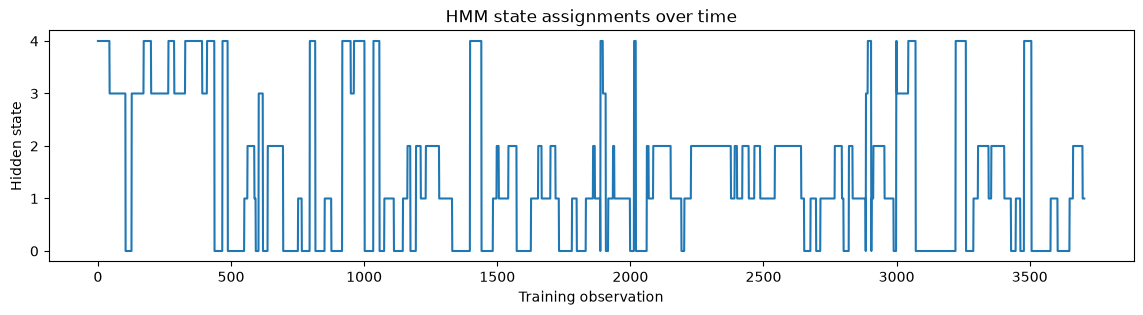

In [354]:
plt.figure(figsize=(14, 3))
plt.plot(states)
plt.xlabel("Training observation")
plt.ylabel("Hidden state")
plt.title("HMM state assignments over time")
plt.show()

In [355]:
s = pd.Series(states)
groups = s.ne(s.shift()).cumsum()
durations = s.groupby(groups).agg(["first", "size"])
durations.columns = ["state", "duration"]

print(durations.groupby("state")["duration"].agg(["count", "mean", "median", "max"]).round(2))  

       count   mean  median  max
state                           
0         35  32.43    28.0  150
1         39  23.87    20.0   59
2         24  34.62    25.0  150
3         10  31.80    29.5   65
4         18  27.28    28.0   64


In [356]:
print("Converged:", model.monitor_.converged)
print("Iterations:", model.monitor_.iter)
print("Log-likelihood history:", list(model.monitor_.history))

Converged: True
Iterations: 146
Log-likelihood history: [-22208.328672194617, -17747.32449985726, -16499.404560809366, -15823.829001486758, -15374.524190562908, -15078.505572240252, -14905.438815518239, -14798.942463139136, -14744.340391822887, -14718.826247856341, -14702.725683317803, -14690.880998636792, -14670.927655563028, -14655.678160713253, -14640.639007763759, -14618.328063692796, -14582.051891224432, -14517.52369077622, -14402.773755947062, -14228.344287117236, -14032.72749653237, -13885.890311820389, -13796.504601197994, -13752.969538525138, -13711.925286129093, -13670.192672940811, -13618.43926519949, -13572.120296974585, -13500.458115421923, -13409.399695390759, -13334.35011945315, -13298.636323213836, -13280.657625519409, -13267.445003114959, -13263.466170888463, -13262.273134959705, -13261.542144285764, -13260.942799176995, -13260.502323044051, -13260.210548718906, -13259.975870252363, -13259.75176423504, -13259.52206282287, -13259.282481206861, -13259.037452044216, -1325

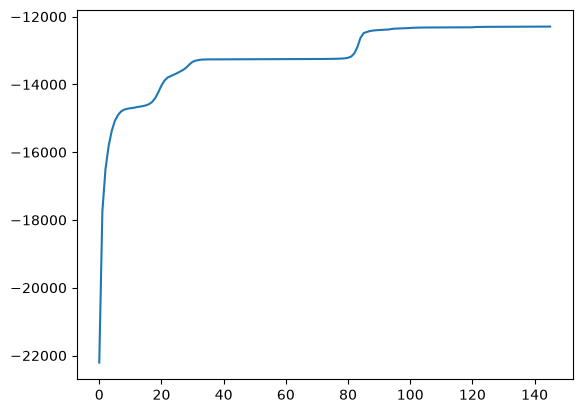

In [357]:
plt.plot(list(model.monitor_.history))

In [358]:
test_df=pd.read_csv('test_df.csv')
test_df =test_df.drop(columns=["Unnamed: 0"])

log_likelihood = model.score(test_df)
print(f"Log-likelihood of the test data: {log_likelihood}")

Log-likelihood of the test data: -12293.846386861871


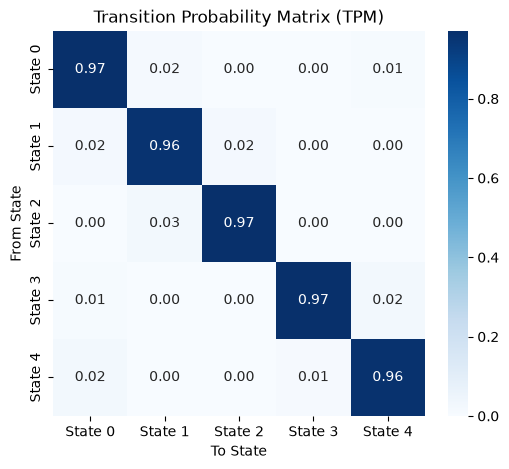

In [359]:
tpm = model.transmat_

# 2. Plot using Seaborn heatmap
plt.figure(figsize=(6, 5))
sns.heatmap(
    tpm,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    xticklabels=[f"State {i}" for i in range(tpm.shape[0])],
    yticklabels=[f"State {i}" for i in range(tpm.shape[0])],
)
plt.title("Transition Probability Matrix (TPM)")
plt.xlabel("To State")
plt.ylabel("From State")
plt.show()

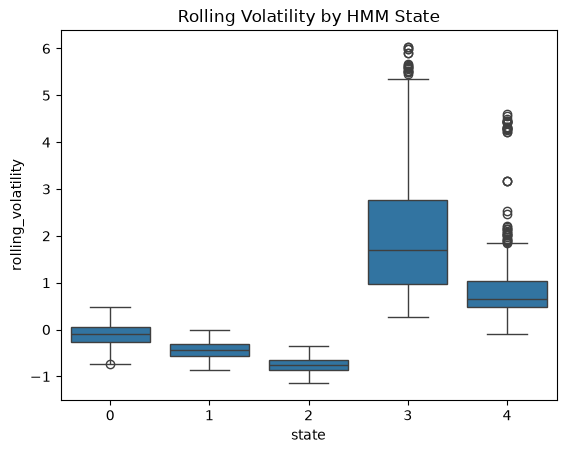

In [360]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.boxplot(data=state_analysis, x="state", y="rolling_volatility")
plt.title("Rolling Volatility by HMM State")
plt.show()

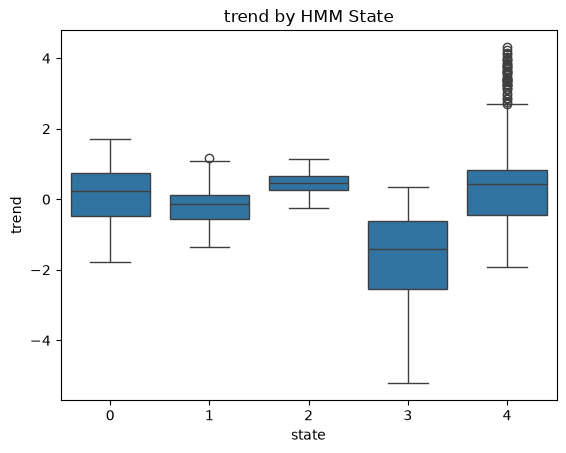

In [361]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.boxplot(data=state_analysis, x="state", y="trend")
plt.title("trend by HMM State")
plt.show()

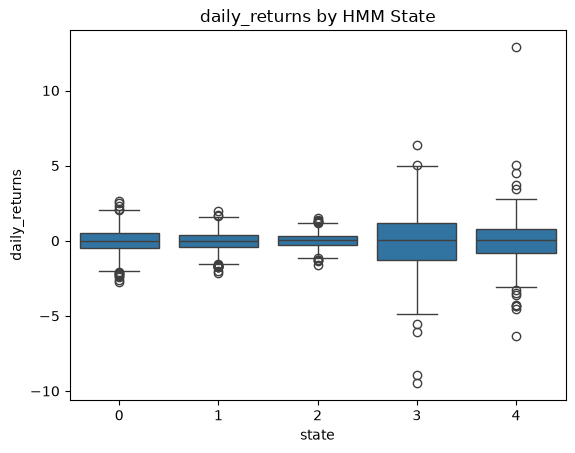

In [362]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.boxplot(data=state_analysis, x="state", y="daily_returns")
plt.title("daily_returns by HMM State")
plt.show()

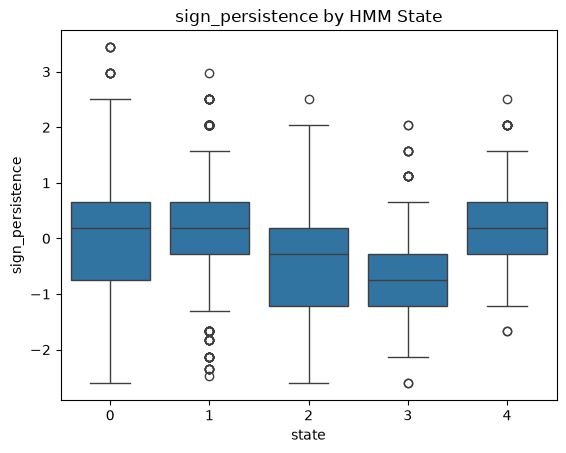

In [363]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.boxplot(data=state_analysis, x="state", y="sign_persistence")
plt.title("sign_persistence by HMM State")
plt.show()

In [364]:
results = []

for n in [3, 4, 5]:
    candidate = hmm.GaussianHMM(
        n_components=n,
        covariance_type="full",
        n_iter=1000,
        random_state=42
    )

    candidate.fit(train_df)

    results.append({
        "states": n,
        "converged": candidate.monitor_.converged,
        "iterations": candidate.monitor_.iter,
        "train_log_likelihood": candidate.score(train_df),
        "AIC": candidate.aic(train_df),
        "BIC": candidate.bic(train_df)
    })

comparison = pd.DataFrame(results).set_index("states")
print(comparison.round(2))

        converged  iterations  train_log_likelihood       AIC       BIC
states                                                                 
3            True         147             -14054.86  28209.72  28520.60
4            True          42             -13262.56  26667.12  27108.57
5            True         146             -12293.85  24775.69  25360.16
